# Intro to Models

In this lecture we will learn about **modeling** data for the first time. After this lesson, you should know what we generally mean by a "model", what linear regression is and how to interpret the output.
But first we need to introduce a new data type: *categorical variables*.

    
1. [Categorical variables](#Categorical-variables)
2. [Models](#Models)
   - [Tables as models](#Tables-as-models)
   - [Modeling Missing Values](#Modeling-Missing-Values)
   - [Linear Regression](#Linear-Regression)


Online Resources:

[Chapter 7.5](https://wesmckinney.com/book/data-cleaning.html#pandas-categorical) of our textbook introduces categorical variables.



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.random import default_rng
import warnings


In [5]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
#Ordinary
#Least
#Squares

est = smf.ols

We will come back to the usefulness of this later.



## Tables as models

For now let us look at our first "model":

In [6]:
titanic = sns.load_dataset('titanic')
titanic["class3"] = (titanic["pclass"]==3)
titanic["male"] = (titanic["sex"]=="male")
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,class3,male
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,True,True
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,False,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,True,False
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,False,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,True,True


Get me the survival rates for men and women separately.

In [7]:
titanic.groupby("sex").survived.mean()
titanic.groupby(["sex","pclass"]).survived.mean()
titanic["SurvPred"] = 1
titanic[titanic.adult_male].SurvPred = 0

titanic
# pd.crosstab(titanic.survived, titanic.SurvPred)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,class3,male,SurvPred
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,True,True,1
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,False,False,1
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,True,False,1
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,False,False,1
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,True,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True,False,True,1
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True,False,False,1
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False,True,False,1
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True,False,True,1


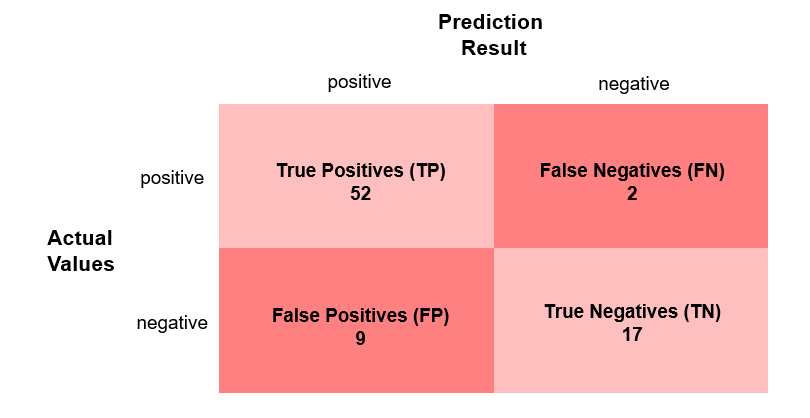

In [8]:
vals1, cts1 = np.unique(titanic["class3"], return_counts=True)
print(cts1)
print(vals1)

[400 491]
[False  True]


In [9]:
print("The mean survival on the Titanic was", np.mean(titanic.survived))

The mean survival on the Titanic was 0.3838383838383838


In [10]:
ConTbl = pd.crosstab(titanic["sex"], titanic["survived"])
ConTbl

survived,0,1
sex,,
female,81,233
male,468,109


What are the estimated survival probabilities?

In [ ]:
#the good old groupby way:
bySex = titanic.groupby("sex").survived
bySex.mean() 

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

In [12]:
p3D = pd.crosstab([titanic["sex"], titanic["class3"]], titanic["survived"])
p3D

survived         0    1
sex    class3          
female False     9  161
       True     72   72
male   False   168   62
       True    300   47

What are the estimated survival probabilities?

In [13]:
#the good old groupby way:
bySex = titanic.groupby(["sex", "class3"]).survived
bySex.mean()

sex     class3
female  False     0.947059
        True      0.500000
male    False     0.269565
        True      0.135447
Name: survived, dtype: float64

The above table can be looked at as a **model**, which is defined as a function which takes *inputs* **x** and "spits out" a *prediction*: 

$y = f(\mathbf{x})$

In our case, the inputs are $x_1=\text{sex}$, $x_2=\text{class3}$, and the output is the estimated survival probability!

It is evident that we could keep adding more *input* variables and make finer and finer grained predictions.

### Linear Models

In [14]:
lsFit = smf.ols('survived ~ sex', titanic).fit()
lsFit.summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,0.7420,0.023,32.171,0.000,0.697,0.787
sex[T.male],-0.5531,0.029,-19.298,0.000,-0.609,-0.497


#### From categorical to numerical relations

In [15]:
url = "https://raw.githubusercontent.com/markusloecher/DataScience2018/master/data/Auto.csv"
auto = pd.read_csv(url)
auto.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name,Manufacturer
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu,chevrolet
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320,buick
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite,plymouth
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst,amc
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino,ford


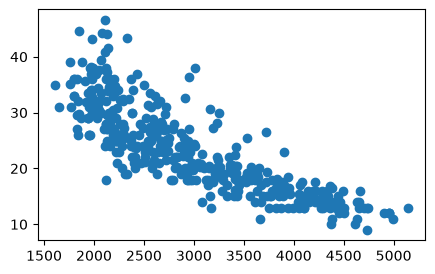

In [16]:
plt.figure(figsize=(5,3))
plt.scatter(x=auto["weight"], y=auto["mpg"]);

## Linear Regression

We can roughly estimate, i.e. "model" this relationship with a straight line:

$$
y = \beta_0 + \beta_1 x
$$

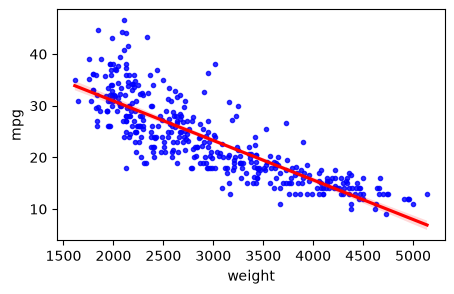

In [17]:
plt.figure(figsize=(5,3))
tmp=sns.regplot(x=auto["weight"], y=auto["mpg"], order=1, ci=95, 
                scatter_kws={'color':'b', 's':9}, line_kws={'color':'r'})

Remind yourself of the definition of the slope of a straight line

![SlopeIllustration](figures/IllustrationSlope.png)

$$
\beta_1 = \frac{\Delta y}{\Delta x} =  \frac{y_2-y_1}{x_2-x_1}
$$

In [48]:

est = smf.ols('mpg ~ weight_tons+cylinders', auto).fit()
est.summary().tables[1]

Predi = 46.2165-0.0076*5000

Predi

auto["weight_tons"] = auto["weight"]/2000


Beta0 = est.params["Intercept"]  # 46.2165
Beta1 = est.params["weight_tons"]  # -15.2947
Beta2 = est.params["cylinders"]
Weight_selected = 5000
Prediction = Beta0 + Beta1*Weight_selected
Prediction
auto["predicted"] = Beta0 + Beta1*auto["weight_tons"] + Beta2*auto["cylinders"]
MSE = ((auto["predicted"]-auto["mpg"])**2).mean()
MSE

#est.summary().tables[1]

np.float64(18.382946233810753)

In [52]:
yHat = est.predict(auto)
r = auto.mpg-yHat
MSE = (r**2).mean()
MSE

np.float64(18.382946233810753)

In [51]:
#Mean prediction model
yHat = auto["mpg"].mean()
r = auto.mpg-yHat
MSE0 = (r**2).mean()
MSE0


np.float64(60.76273844231571)

In [54]:
R2 = 1-MSE/MSE0
R2

np.float64(0.6974634997521983)

### Squared loss versus absolute loss

So far, we have used **ordinary least squares (OLS)**. It chooses the intercept and slope to minimize the sum of **squared residuals**:

$$
\sum_{i=1}^n (y_i-\hat y_i)^2.
$$

We can instead minimize the sum of **absolute residuals**:

$$
\sum_{i=1}^n |y_i-\hat y_i|.
$$

This is often called *least absolute deviations* (LAD) regression. For a linear model, minimizing absolute errors estimates the **conditional median** rather than the conditional mean. In Statsmodels, we can fit this model using median quantile regression (`q=0.5`).

The absolute loss is less sensitive to large residuals than squared loss: a residual twice as large contributes twice as much, rather than four times as much.

In [19]:
# OLS: minimize the sum of squared residuals
ols_fit = smf.ols('mpg ~ weight', data=auto).fit()

# LAD: minimize the sum of absolute residuals (median regression)
lad_fit = smf.quantreg('mpg ~ weight', data=auto).fit(q=0.5)

pd.DataFrame({
    "OLS (squared loss)": ols_fit.params,
    "LAD (absolute loss)": lad_fit.params
})

,OLS (squared loss),LAD (absolute loss)
Intercept,46.216525,44.103020
weight,-0.007647,-0.007105


The two fitted lines need not be identical. The difference comes from the loss function, not from the formula: both models use the same linear relationship, `mpg ~ weight`.

Let's compare the fitted lines.

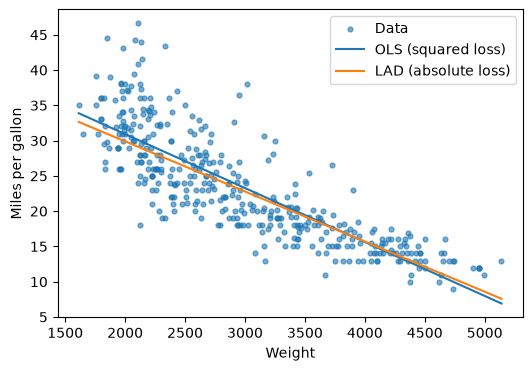

In [20]:
plt.figure(figsize=(6, 4))
plt.scatter(auto["weight"], auto["mpg"], s=12, alpha=0.6, label="Data")

x_grid = np.linspace(auto["weight"].min(), auto["weight"].max(), 100)
plt.plot(x_grid, ols_fit.predict({"weight": x_grid}), label="OLS (squared loss)")
plt.plot(x_grid, lad_fit.predict({"weight": x_grid}), label="LAD (absolute loss)")

plt.xlabel("Weight")
plt.ylabel("Miles per gallon")
plt.legend()
plt.show()

### Using Scikit-learn

Statsmodels is convenient when we want a statistical summary, including standard errors and hypothesis tests. **Scikit-learn** provides a common interface for fitting models and is especially useful in predictive workflows.


There is one small complication: Scikit-learn generally expects the response `y` and the predictor matrix `X` separately. It does not use formula strings such as `mpg ~ weight` directly.

This is where **Patsy** comes in. Patsy translates a formula into the design matrices that Scikit-learn expects. It also handles categorical variables and interactions in formulas.

In [55]:
from patsy import dmatrices
from sklearn.linear_model import LinearRegression, QuantileRegressor

# Translate the formula into a response vector y and a design matrix X
y, X = dmatrices('mpg ~ weight', data=auto, return_type='dataframe')

# The design matrix already contains an intercept column.
# Therefore, set fit_intercept=False in Scikit-learn.
sk_ols = LinearRegression(fit_intercept=False)
sk_ols.fit(X, y)

# QuantileRegressor with q=0.5 minimizes absolute loss.
# alpha=0 means that no additional L1 regularization is applied.
sk_lad = QuantileRegressor(
    quantile=0.5, alpha=0.0, fit_intercept=False, solver="highs"
)
sk_lad.fit(X, y.to_numpy().ravel())

pd.DataFrame({
    "Statsmodels OLS": ols_fit.params,
    "Scikit-learn OLS": sk_ols.coef_.ravel(),
    "Statsmodels LAD": lad_fit.params,
    "Scikit-learn LAD": sk_lad.coef_
}, index=X.columns)

,Statsmodels OLS,Scikit-learn OLS,Statsmodels LAD,Scikit-learn LAD
Intercept,46.216525,46.216525,44.103020,44.103020
weight,-0.007647,-0.007647,-0.007105,-0.007105


Notice that Patsy has created a column called `Intercept`. Since the intercept is already part of `X`, we used `fit_intercept=False` in both Scikit-learn estimators. Otherwise, we would include an intercept twice.

The formulas are now separated from the estimation method: we can change the formula in `dmatrices()` and pass the resulting design matrices to different Scikit-learn estimators. For example, `mpg ~ weight + C(origin)` adds a categorical predictor, and `mpg ~ weight * C(origin)` also includes interactions.

In [22]:
np.corrcoef(auto["weight"], auto["mpg"])

array([[ 1.        , -0.83224421],
       [-0.83224421,  1.        ]])

### Palmer Penguins


In [23]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

penguins = sns.load_dataset("penguins")
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


# Simple Summary Stats

* How many on each island ?
* What are the mean weight and flipper length ?
* What do the distributions of weight and flipper length look like?
* Are there differences in the body mass of penguins by sex within each species?

-------------------

- Repeat all of the above grouping by species.
- Try numerical and graphical summaries

           species  bill_length_mm  bill_depth_mm  flipper_length_mm  \
island                                                                 
Biscoe         168             167            167                167   
Dream          124             124            124                124   
Torgersen       52              51             51                 51   

           body_mass_g  sex  
island                       
Biscoe             167  163  
Dream              124  123  
Torgersen           51   47           body_mass_g
sex                
Female  3862.272727
Male    4545.684524


<Axes: xlabel='flipper_length_mm'>

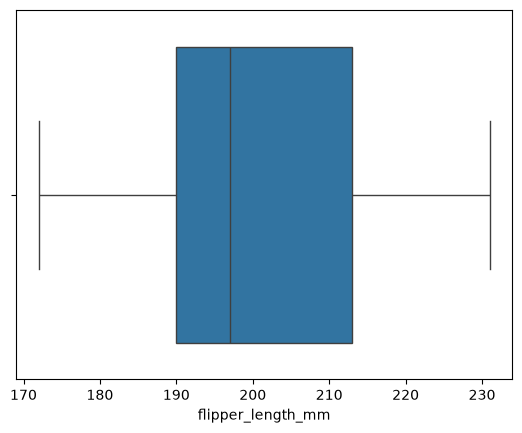

In [59]:
print(
penguins.groupby("island").count(),
penguins.groupby("sex").agg({"body_mass_g":"mean"}))
sns.boxplot(penguins, x = penguins["flipper_length_mm"])

## Regression

* Fit a regression line  `bill_length_mm` vs `bill_depth_mm`
* Plot the line on top of a scatter plot
* Report and interpret the estimated intercept and slope.

**Compare predictions with a simple benchmark**

- Consider a very simple prediction model that always predicts the sample mean of bill_depth_mm.
- Calculate its MSE and MAE.
- How much better is your regression model than this benchmark?

**Assess the quality of the regression**

Calculate the following measures:
- \(R^2\)
- Mean squared error (MSE)
- Mean absolute error (MAE)
Then answer:
- What does each measure tell us?
- Which of the three measures depends on the units of the dependent variable?
- Can you compare the MSE and MAE numerically? What do their magnitudes tell you



Add a categorical variable !